# Practical 8: AND Gate with Perceptron Learning Algorithm

Implement the perceptron learning rule from scratch. The only model operations below are NumPy arithmetic and explicit Python loops; no built-in ML, neural-network, or perceptron implementation is used.

## AND truth table and learning rule

For each example, compute `step(w·x + b)`. Update weights and bias by `learning_rate × (target − prediction)`. Stop when an epoch makes no mistakes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Truth table stored as a pandas DataFrame for clear display.
data = pd.DataFrame({"x1": [0, 0, 1, 1], "x2": [0, 1, 0, 1], "target": [0, 0, 0, 1]})
display(data)
X = data[["x1", "x2"]].to_numpy(dtype=float)
y = data["target"].to_numpy(dtype=int)

def step(value):
    return 1 if value >= 0 else 0

def train_perceptron(X, y, learning_rate=0.1, max_epochs=100):
    weights = np.zeros(X.shape[1], dtype=float)
    bias = 0.0
    for epoch in range(max_epochs):
        mistakes = 0
        for inputs, target in zip(X, y):
            prediction = step(np.dot(inputs, weights) + bias)
            update = learning_rate * (target - prediction)
            weights += update * inputs
            bias += update
            if update != 0:
                mistakes += 1
        if mistakes == 0:
            print("Converged after", epoch + 1, "epochs")
            break
    return weights, bias

weights, bias = train_perceptron(X, y)
predictions = np.array([step(np.dot(row, weights) + bias) for row in X])
results = data.copy()
results["prediction"] = predictions
print("Weights:", weights, "Bias:", bias)
display(results)
assert np.array_equal(predictions, y), "The perceptron did not learn the AND truth table."

,x1,x2,target
0,0,0,0
1,0,1,0
2,1,0,0
3,1,1,1


Converged after 4 epochs
Weights: [0.2 0.1] Bias: -0.20000000000000004


,x1,x2,target,prediction
0,0,0,0,0
1,0,1,0,0
2,1,0,0,0
3,1,1,1,1


## Plot the truth table

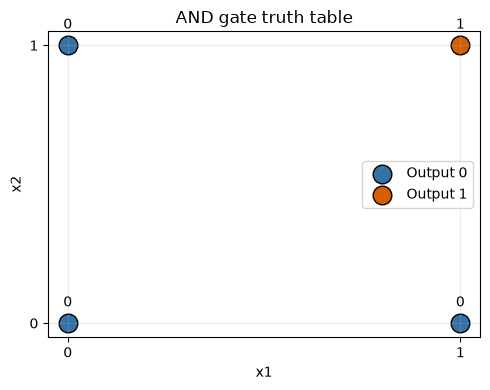

In [2]:
fig, ax = plt.subplots(figsize=(5, 4))
for target, color, label in [(0, "#3572a5", "Output 0"), (1, "#d55e00", "Output 1")]:
    mask = y == target
    ax.scatter(X[mask, 0], X[mask, 1], c=color, s=180, edgecolor="black", label=label)
for x1, x2, target in zip(X[:, 0], X[:, 1], y):
    ax.annotate(str(target), (x1, x2), xytext=(0, 12), textcoords="offset points", ha="center")
ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="x1", ylabel="x2", title="AND gate truth table")
ax.legend(); ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

## Conclusion

The perceptron finds weights and bias that classify all four AND input combinations correctly. This notebook runs without the heart attack CSV or the shared implementation script.